# Federated Transfer Learning Across Heterogeneous Medical Imaging Domains

Extension of the earlier binary-label experiment. The previous notebook answered one question
("which federated algorithm reaches the highest accuracy?"). This version is restructured around
a broader study:

**Can federated transfer learning build a useful general-purpose model across heterogeneous medical
imaging domains, and what does it cost in accuracy, communication, privacy and interpretability
compared to centralized training?**

Sub-questions actually addressed by the code below:

1. Does moving from the collapsed binary task to the native multiclass tasks change the ranking and
   the behaviour of the federated algorithms?
2. How far below centralized training does federated training sit, and how far above isolated
   local-only training? (Local-only is the baseline that justifies federation at all; centralized is
   the upper bound that federation gives up.)
3. Does a single shared 25-way head over the union of all five label spaces produce a usable
   general-purpose model, or does modality heterogeneity break it?
4. What is the real communication cost of each method, measured from the tensors the code actually
   exchanges?
5. Why does Federated Distillation underperform here, and is it a property of the method or of the
   reference-set size / implementation?
6. Does a federatively pretrained backbone help a *new* disease with limited data, beyond what plain
   ImageNet pretraining already gives?
7. What do the models look at (Grad-CAM), and do the five clients converge on a shared
   representation (CKA, linear probes, embeddings)?

**Nothing in this notebook is pre-filled with numbers.** Every table and figure is produced from the
run. Sections that were not executed print "not run" rather than a value.

### Relationship to published work

None of the algorithms here are new. FedAvg (McMahan et al., 2017), FedProx (Li et al., 2020),
FedAdam/FedOpt (Reddi et al., 2021), Federated Distillation / FedDF (Jeong et al., 2018; Lin et al.,
2020), local BatchNorm / FedBN (Li et al., 2021), shared-backbone-with-personalized-head (Collins et
al., 2021, FedRep), Grad-CAM (Selvaraju et al., 2017) and CKA (Kornblith et al., 2019) are all
established. The datasets are MedMNIST v2 (Yang et al., 2023). The contribution of this project is
the experimental study: the specific combination, the multi-domain setting, and the measured
trade-offs reported below.

---
## 1. Setup

In [1]:
import sys
!{sys.executable} -m pip install -q torch torchvision medmnist scikit-learn

In [2]:
import os, time, json, copy, random, itertools
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset, ConcatDataset
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
import warnings; warnings.filterwarnings('ignore')

from medmnist import (PneumoniaMNIST, BreastMNIST, DermaMNIST, PathMNIST,
                      RetinaMNIST, BloodMNIST)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

print('Device :', DEVICE, '| PyTorch', torch.__version__)
if DEVICE.type == 'cpu':
    print('Running on CPU. Enable a GPU runtime before running the full grid.')

---
## 2. Configuration

`label_space` controls the whole experiment:

- `binary` reproduces the original setup (every client collapsed to normal/abnormal).
- `native` gives every client its own native classes and a **local** classification head; only the
  backbone is federated. This is the personalized setting.
- `union` concatenates the five label spaces into one shared output space (2+2+7+9+5 = 25 classes)
  and federates the head as well. This is the general-purpose multidisease model: one network, one
  output layer, every disease state of every modality.

`classes_per_client` restricts each client to its k most frequent native classes, which is how the
3-class and 4-class experiments are produced. `None` keeps all native classes.

`RUN` switches individual experiments on and off so the notebook can be executed in stages.

In [3]:
CONFIG = {
    'num_rounds'          : 8,
    'local_epochs'        : 4,
    'batch_size'          : 64,
    'learning_rate'       : 0.0005,
    'image_size'          : 96,
    'mu_prox'             : 0.01,
    'server_lr'           : 0.1,
    'beta1'               : 0.9,
    'beta2'               : 0.99,
    'tau'                 : 1e-3,
    'max_train_per_client': 2000,
    'max_val_per_client'  : 500,
    'max_test_per_client' : 1000,
    'label_space'         : 'union',
    'classes_per_client'  : None,
    'num_public'          : 250,
    'distill_epochs'      : 8,
    'temperature'         : 4.0,
    'seeds'               : [0],
    'new_disease'         : 'BloodMNIST',
    'new_disease_epochs'  : 10,
    'new_disease_train'   : 1500,
}

RUN = {
    'centralized'      : True,
    'local_only'       : True,
    'federated'        : True,
    'distillation'     : True,
    'multiclass_sweep' : True,
    'distill_ablation' : True,
    'privacy'          : True,
    'new_disease'      : True,
    'explainability'   : True,
    'representation'   : True,
}

BINARY_MAPS = {
    'PneumoniaMNIST' : {0: 0, 1: 1},
    'BreastMNIST'    : {0: 1, 1: 0},
    'DermaMNIST'     : {0: 1, 1: 1, 2: 0, 3: 0, 4: 1, 5: 0, 6: 0},
    'PathMNIST'      : {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 1, 8: 1},
    'RetinaMNIST'    : {0: 0, 1: 1, 2: 1, 3: 1, 4: 1},
}

DATASET_LOADERS = {
    'PneumoniaMNIST' : PneumoniaMNIST,
    'BreastMNIST'    : BreastMNIST,
    'DermaMNIST'     : DermaMNIST,
    'PathMNIST'      : PathMNIST,
    'RetinaMNIST'    : RetinaMNIST,
}

MODALITY = {
    'PneumoniaMNIST' : 'chest X-ray',
    'BreastMNIST'    : 'breast ultrasound',
    'DermaMNIST'     : 'dermatoscopy',
    'PathMNIST'      : 'histopathology',
    'RetinaMNIST'    : 'fundus photography',
}

RESULTS = []
HISTORY = []

def record(store, **kw):
    store.append(kw)
    return kw

NameError: name 'PneumoniaMNIST' is not defined

---
## 3. Data

Same preprocessing as before. Two changes that matter:

- the MedMNIST **validation** split is now loaded and used as the reference/public pool for
  Federated Distillation. In the previous version that pool was taken from the *test* sets, which
  leaks test data into training.
- the label map is derived once from the training split and reused for val and test, so the class
  indices are consistent.

In [4]:
imagenet_mean, imagenet_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

transform_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
transform_test = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class MappedDataset(Dataset):
    def __init__(self, base, indices, label_map, offset=0):
        self.base = base
        self.indices = indices
        self.label_map = label_map
        self.offset = offset
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, lab = self.base[self.indices[i]]
        native = int(np.array(lab).reshape(-1)[0])
        return img, self.label_map[native] + self.offset

def dataset_labels(ds):
    return np.array(ds.labels).reshape(-1)

def make_label_map(name, y, label_space, k):
    if label_space == 'binary':
        return BINARY_MAPS[name]
    classes = sorted(np.unique(y).tolist())
    if k is not None:
        counts = {c: int((y == c).sum()) for c in classes}
        classes = sorted(sorted(classes, key=lambda c: -counts[c])[:k])
    return {c: i for i, c in enumerate(classes)}

def build_split(loader_class, split, transform, cap, label_map, seed):
    base = loader_class(split=split, transform=transform, download=True)
    y = dataset_labels(base)
    keep = np.where(np.isin(y, list(label_map)))[0]
    if cap is not None and len(keep) > cap:
        keep = np.random.RandomState(seed).choice(keep, cap, replace=False)
    return MappedDataset(base, keep.tolist(), label_map)

def make_clients(label_space=None, classes_per_client=None, seed=0):
    label_space = label_space or CONFIG['label_space']
    if classes_per_client is None:
        classes_per_client = CONFIG['classes_per_client']
    names = list(DATASET_LOADERS)
    train, val, test, num_classes = [], [], [], []
    for name in names:
        loader_class = DATASET_LOADERS[name]
        probe = loader_class(split='train', download=True)
        label_map = make_label_map(name, dataset_labels(probe), label_space, classes_per_client)
        train.append(build_split(loader_class, 'train', transform_train,
                                 CONFIG['max_train_per_client'], label_map, seed))
        val.append(build_split(loader_class, 'val', transform_test,
                               CONFIG['max_val_per_client'], label_map, seed))
        test.append(build_split(loader_class, 'test', transform_test,
                                CONFIG['max_test_per_client'], label_map, seed))
        num_classes.append(len(set(label_map.values())))

    offsets = [0] * len(names)
    if label_space == 'union':
        offsets = np.cumsum([0] + num_classes[:-1]).tolist()
        for off, tr, va, te in zip(offsets, train, val, test):
            tr.offset = va.offset = te.offset = off

    class_ids = [list(range(o, o + n)) for o, n in zip(offsets, num_classes)]
    total_classes = sum(num_classes) if label_space == 'union' else max(num_classes)

    return {
        'names'        : names,
        'train'        : train,
        'val'          : val,
        'test'         : test,
        'num_classes'  : num_classes,
        'class_ids'    : class_ids,
        'total_classes': total_classes,
        'label_space'  : label_space,
        'sizes'        : [len(d) for d in train],
        'train_loaders': [DataLoader(d, batch_size=CONFIG['batch_size'], shuffle=True) for d in train],
        'test_loaders' : [DataLoader(d, batch_size=128, shuffle=False) for d in test],
    }

def head_size(clients, i):
    return clients['total_classes'] if clients['label_space'] == 'union' else clients['num_classes'][i]

def label_counts(ds, num_classes):
    y = dataset_labels(ds.base)[ds.indices]
    mapped = np.array([ds.label_map[int(v)] for v in y])
    return np.bincount(mapped, minlength=num_classes)

def describe(clients):
    rows = []
    for i, name in enumerate(clients['names']):
        counts = label_counts(clients['train'][i], clients['num_classes'][i])
        rows.append({
            'client': name,
            'modality': MODALITY[name],
            'classes': clients['num_classes'][i],
            'train': len(clients['train'][i]),
            'val': len(clients['val'][i]),
            'test': len(clients['test'][i]),
            'imbalance': round(float(counts.max() / max(counts.min(), 1)), 2),
        })
    return rows

CLIENTS = make_clients()
TABLE1 = describe(CLIENTS)
for r in TABLE1:
    print(r)
print('total classes in shared output space:', CLIENTS['total_classes'])

NameError: name 'transforms' is not defined

---
## 4. Evaluation

Accuracy alone is not informative on these datasets (PneumoniaMNIST and PathMNIST are strongly
imbalanced, and in `union` mode a client's classes are a small slice of the output space). Each
evaluation returns accuracy, macro precision/recall/F1, per-class recall, the confusion matrix and
an AUC where one is mathematically defined.

In `union` mode two accuracies are reported:

- **within-client accuracy**: argmax restricted to the client's own block of classes, i.e. the
  clinically realistic case where the modality of the incoming image is known.
- **open accuracy**: argmax over all 25 logits, plus `outside_rate`, the fraction of test images
  assigned to a class belonging to a different modality. `outside_rate` is the measurement that
  tells us whether the general-purpose head is actually usable without knowing the modality.

In [5]:
def collect_predictions(model, loader, device=DEVICE):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            out = model(imgs.to(device))
            ps.append(F.softmax(out, dim=1).cpu().numpy())
            ys.append(labels.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def safe_auc(y_local, p_local):
    n = p_local.shape[1]
    try:
        if n == 2:
            return float(roc_auc_score(y_local, p_local[:, 1]))
        if len(np.unique(y_local)) < n:
            return None
        return float(roc_auc_score(y_local, p_local, multi_class='ovr',
                                   average='macro', labels=list(range(n))))
    except ValueError:
        return None

def compute_metrics(y, prob, class_ids):
    ids = np.array(class_ids)
    pred = ids[prob[:, ids].argmax(1)]
    acc = accuracy_score(y, pred)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=ids,
                                                    average='macro', zero_division=0)
    _, per_class_recall, _, support = precision_recall_fscore_support(
        y, pred, labels=ids, average=None, zero_division=0)
    p_local = prob[:, ids]
    p_local = p_local / p_local.sum(1, keepdims=True).clip(1e-12)
    y_local = np.searchsorted(ids, y)
    out = {
        'accuracy'  : float(acc),
        'precision' : float(pr),
        'recall'    : float(rc),
        'f1'        : float(f1),
        'auc'       : safe_auc(y_local, p_local),
        'per_class_recall': [round(float(v), 4) for v in per_class_recall],
        'support'   : [int(v) for v in support],
        'confusion' : confusion_matrix(y, pred, labels=ids).tolist(),
    }
    if prob.shape[1] > len(ids):
        open_pred = prob.argmax(1)
        out['open_accuracy'] = float((open_pred == y).mean())
        out['outside_rate'] = float((~np.isin(open_pred, ids)).mean())
    return out

def evaluate_client(model, loader, class_ids):
    y, prob = collect_predictions(model, loader)
    return compute_metrics(y, prob, class_ids)

def mean_over_clients(metric_list, key):
    vals = [m[key] for m in metric_list if m.get(key) is not None]
    return float(np.mean(vals)) if vals else None

---
## 5. Model

Unchanged from the previous version except that the head width is now a parameter and the backbone
can be exposed separately for Grad-CAM and for representation analysis. The stem (`conv1`, `bn1`)
stays frozen; everything else is fine-tuned.

Which parameters are federated depends on the mode:

| mode | backbone conv | BatchNorm affine + running stats | head |
|---|---|---|---|
| `binary` / `union` | federated | **local** (FedBN) | federated |
| `native` | federated | **local** | **local** (per-client heads) |

BatchNorm is never federated in any mode, following FedBN (Li et al., 2021) — the earlier collapse
to constant predictions is exactly the failure mode that paper describes for multi-source medical
imaging.

In [6]:
class FederatedModel(nn.Module):
    def __init__(self, num_classes, pretrained=True, freeze_stem=True):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet18(weights=weights)
        backbone.fc = nn.Identity()
        self.backbone = backbone
        if freeze_stem:
            for p in self.backbone.conv1.parameters():
                p.requires_grad = False
            for p in self.backbone.bn1.parameters():
                p.requires_grad = False
        self.head = nn.Sequential(
            nn.Linear(512, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def features(self, x):
        return self.backbone(x)
    def forward(self, x):
        return self.head(self.backbone(x))

def bn_param_names(model):
    names = set()
    for name, module in model.named_modules():
        if isinstance(module, nn.BatchNorm2d):
            names.add(name + '.weight')
            names.add(name + '.bias')
    return names

def federated_names(model, local_head=False):
    bn = bn_param_names(model)
    out = []
    for n, p in model.named_parameters():
        if not p.requires_grad or n in bn:
            continue
        if local_head and n.startswith('head.'):
            continue
        out.append(n)
    return out

def extract_state(model, names):
    params = dict(model.named_parameters())
    return {n: params[n].detach().clone() for n in names}

def load_state(model, state):
    full = model.state_dict()
    for k, v in state.items():
        full[k] = v
    model.load_state_dict(full)

def state_bytes(state):
    return sum(v.numel() * v.element_size() for v in state.values())

_probe = FederatedModel(CLIENTS['total_classes'])
print('total parameters     :', f'{sum(p.numel() for p in _probe.parameters()):,}')
print('trainable            :', f'{sum(p.numel() for p in _probe.parameters() if p.requires_grad):,}')
print('federated (union)    :', f'{sum(_probe.state_dict()[n].numel() for n in federated_names(_probe)):,}')
print('federated (native)   :', f'{sum(_probe.state_dict()[n].numel() for n in federated_names(_probe, local_head=True)):,}')
print('kept local (BN)      :', f'{sum(_probe.state_dict()[n].numel() for n in bn_param_names(_probe)):,}')
del _probe

---
## 6. Local training, differential privacy mechanism, communication accounting

`train_local` covers FedAvg/FedAdam (no proximal term), FedProx (`mu > 0`) and the centralized and
local-only baselines.

`privatize` implements the update-level Gaussian mechanism used in the privacy experiment: the
client update is clipped to an L2 norm `C` and Gaussian noise with standard deviation
`noise_multiplier * C` is added before it leaves the client. **This is the mechanism, not a formal
guarantee.** With 5 fixed clients, every round, and no subsampling, there is no meaningful
(epsilon, delta) to report — see the discussion in Section 14. The experiment measures the
accuracy cost of the noise, and nothing stronger is claimed.

Communication is counted from the tensors the code actually moves: `state_bytes` on the exact
dictionaries that are sent up and broadcast down.

In [7]:
def train_local(model, loader, optimizer, epochs, global_params=None, mu=0.0, device=DEVICE):
    model.train()
    ce = nn.CrossEntropyLoss()
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = ce(model(imgs), labels)
            if global_params is not None and mu > 0:
                prox = sum(((p - global_params[n]) ** 2).sum()
                           for n, p in model.named_parameters() if n in global_params)
                loss = loss + (mu / 2) * prox
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

def privatize(model, global_state, clip_norm, noise_multiplier, device=DEVICE):
    params = dict(model.named_parameters())
    delta = {n: params[n].detach() - global_state[n] for n in global_state}
    total = torch.sqrt(sum((d.float() ** 2).sum() for d in delta.values()))
    scale = min(1.0, clip_norm / (total.item() + 1e-12))
    new_state = {}
    for n, d in delta.items():
        d = d * scale
        if noise_multiplier > 0:
            d = d + torch.normal(0.0, noise_multiplier * clip_norm, size=d.shape, device=device)
        new_state[n] = global_state[n] + d
    load_state(model, new_state)
    return float(total.item())

class Comm:
    def __init__(self):
        self.up = 0
        self.down = 0
    def send(self, nbytes, n=1):
        self.up += nbytes * n
    def receive(self, nbytes, n=1):
        self.down += nbytes * n
    def total_mb(self):
        return (self.up + self.down) / 1e6
    def summary(self, rounds, n_clients):
        return {
            'up_mb': self.up / 1e6,
            'down_mb': self.down / 1e6,
            'total_mb': self.total_mb(),
            'mb_per_client_per_round': self.total_mb() / max(rounds * n_clients, 1),
            'rounds': rounds,
        }

NameError: name 'DEVICE' is not defined

---
## 7. Baselines: centralized and local-only

Two reference points are needed to say anything about federated learning.

**Centralized** pools all five training sets into one dataset and trains one model with the same
architecture, preprocessing, splits and label space. It is the upper bound that federation gives up.
It requires a shared output space, so it runs in `binary` or `union` mode. One caveat is recorded
honestly rather than hidden: the centralized model sees mixed-modality batches, so its BatchNorm
layers are shared across modalities, whereas the federated clients keep BatchNorm local. That is a
real difference between the two settings, not an experimental artefact that can be removed — a
centralized model has no client identity to personalize on. A second centralized variant with
per-modality BatchNorm would be a different (and non-deployable) model.

**Local-only** trains each client alone on its own data for the same total number of epochs
(`num_rounds * local_epochs`), with no communication at all. This is the baseline that answers "why
federate": if federation does not beat local-only, there is no reason to pay the communication and
privacy cost.

Epoch budgets are matched per client. The centralized model necessarily performs more gradient steps
per epoch because its dataset is five times larger; wall-clock time is reported alongside so the
comparison is visible rather than assumed away.

In [8]:
def run_centralized(clients, seed=0, epochs=None, setting='main'):
    set_seed(seed)
    epochs = epochs or CONFIG['num_rounds'] * CONFIG['local_epochs']
    pooled = ConcatDataset(clients['train'])
    loader = DataLoader(pooled, batch_size=CONFIG['batch_size'], shuffle=True)
    model = FederatedModel(clients['total_classes']).to(DEVICE)
    opt = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=CONFIG['learning_rate'])
    t0 = time.time()
    train_local(model, loader, opt, epochs)
    elapsed = time.time() - t0
    per_client = [evaluate_client(model, ld, ids)
                  for ld, ids in zip(clients['test_loaders'], clients['class_ids'])]
    for i, (name, m) in enumerate(zip(clients['names'], per_client)):
        record(RESULTS, experiment='centralized', method='Centralized', client=name, seed=seed,
               label_space=clients['label_space'], classes=clients['num_classes'][i], setting=setting,
               time_s=elapsed, up_mb=0.0, down_mb=0.0, rounds=0, **{k: v for k, v in m.items()
               if k not in ('confusion', 'per_class_recall', 'support')})
    print(f'centralized | {epochs} epochs | {elapsed:.0f}s | mean acc '
          f'{mean_over_clients(per_client, "accuracy"):.4f} | mean F1 {mean_over_clients(per_client, "f1"):.4f}')
    return {'model': model, 'metrics': per_client, 'time_s': elapsed}

def run_local_only(clients, seed=0, epochs=None, setting='main'):
    set_seed(seed)
    epochs = epochs or CONFIG['num_rounds'] * CONFIG['local_epochs']
    out = []
    t0 = time.time()
    for i, name in enumerate(clients['names']):
        model = FederatedModel(head_size(clients, i)).to(DEVICE)
        opt = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=CONFIG['learning_rate'])
        train_local(model, clients['train_loaders'][i], opt, epochs)
        m = evaluate_client(model, clients['test_loaders'][i], clients['class_ids'][i])
        out.append(m)
        record(RESULTS, experiment='local_only', method='Local-only', client=name, seed=seed,
               label_space=clients['label_space'], classes=clients['num_classes'][i],
               setting=setting, time_s=time.time() - t0, up_mb=0.0, down_mb=0.0, rounds=0,
               **{k: v for k, v in m.items() if k not in ('confusion', 'per_class_recall', 'support')})
        print(f'  local-only {name:16s} acc {m["accuracy"]:.4f} f1 {m["f1"]:.4f}')
    print(f'local-only | mean acc {mean_over_clients(out, "accuracy"):.4f} | '
          f'mean F1 {mean_over_clients(out, "f1"):.4f}')
    return {'metrics': out}

---
## 8. Federated algorithms

FedAvg, FedProx and FedAdam share one loop; the only differences are the proximal term during local
training and the server-side update rule. Each client is evaluated with its own local BatchNorm and,
in `native` mode, its own head — this is a personalized federated model, and the evaluation
protocol is stated explicitly rather than left implicit.

Optionally a differential-privacy mechanism is applied to every client update before aggregation.

In [9]:
def aggregate(states, sizes):
    total = sum(sizes)
    keys = list(states[0])
    return {k: sum(states[i][k].float() * (sizes[i] / total) for i in range(len(states))) for k in keys}

def run_federated(clients, algo='fedavg', seed=0, rounds=None, dp=None, setting='main', verbose=True):
    set_seed(seed)
    rounds = rounds or CONFIG['num_rounds']
    local_head = clients['label_space'] == 'native'
    n = len(clients['names'])

    locals_ = [FederatedModel(head_size(clients, i)).to(DEVICE) for i in range(n)]
    opts = [optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=CONFIG['learning_rate'])
            for m in locals_]
    global_model = FederatedModel(head_size(clients, 0)).to(DEVICE)
    fed_names = federated_names(global_model, local_head=local_head)
    comm = Comm()
    server_m, server_v = {}, {}
    label = {'fedavg': 'FedAvg', 'fedprox': 'FedProx', 'fedadam': 'FedAdam'}[algo]
    if dp is not None:
        label += f" (DP C={dp['clip']} s={dp['noise']})"

    t0 = time.time()
    for rnd in range(1, rounds + 1):
        g_state = extract_state(global_model, fed_names)
        nbytes = state_bytes(g_state)
        for m in locals_:
            load_state(m, g_state)
            comm.receive(nbytes)

        for i, m in enumerate(locals_):
            train_local(m, clients['train_loaders'][i], opts[i], CONFIG['local_epochs'],
                        global_params=g_state if algo == 'fedprox' else None,
                        mu=CONFIG['mu_prox'] if algo == 'fedprox' else 0.0)
            if dp is not None:
                privatize(m, g_state, dp['clip'], dp['noise'])

        client_states = [extract_state(m, fed_names) for m in locals_]
        for s in client_states:
            comm.send(state_bytes(s))
        avg = aggregate(client_states, clients['sizes'])

        if algo == 'fedadam':
            new_state = {}
            for k in avg:
                delta = avg[k] - g_state[k].float()
                if k not in server_m:
                    server_m[k] = torch.zeros_like(delta)
                    server_v[k] = torch.full_like(delta, CONFIG['tau'] ** 2)
                server_m[k] = CONFIG['beta1'] * server_m[k] + (1 - CONFIG['beta1']) * delta
                server_v[k] = CONFIG['beta2'] * server_v[k] + (1 - CONFIG['beta2']) * delta ** 2
                new_state[k] = (g_state[k].float() + CONFIG['server_lr'] * server_m[k]
                                / (torch.sqrt(server_v[k]) + CONFIG['tau']))
            load_state(global_model, new_state)
        else:
            load_state(global_model, avg)

        metrics = [evaluate_client(m, ld, ids)
                   for m, ld, ids in zip(locals_, clients['test_loaders'], clients['class_ids'])]
        for name, mt in zip(clients['names'], metrics):
            record(HISTORY, method=label, algo=algo, seed=seed, round=rnd, client=name,
                   label_space=clients['label_space'], accuracy=mt['accuracy'], f1=mt['f1'],
                   cum_mb=comm.total_mb(), elapsed_s=time.time() - t0)
        if verbose:
            accs = ' | '.join(f'{nm[:5]} {mt["accuracy"]:.3f}' for nm, mt in zip(clients['names'], metrics))
            print(f'  {label} r{rnd:02d} | mean acc {mean_over_clients(metrics, "accuracy"):.4f} | '
                  f'mean f1 {mean_over_clients(metrics, "f1"):.4f} | {accs}')

    elapsed = time.time() - t0
    summary = comm.summary(rounds, n)
    for i, (name, mt) in enumerate(zip(clients['names'], metrics)):
        record(RESULTS, experiment='federated' if dp is None else 'privacy', method=label, algo=algo,
               client=name, seed=seed, label_space=clients['label_space'],
               classes=clients['num_classes'][i], setting=setting, time_s=elapsed,
               dp_clip=None if dp is None else dp['clip'],
               dp_noise=None if dp is None else dp['noise'],
               up_mb=summary['up_mb'], down_mb=summary['down_mb'], rounds=rounds,
               **{k: v for k, v in mt.items() if k not in ('confusion', 'per_class_recall', 'support')})
    print(f'{label} | mean acc {mean_over_clients(metrics, "accuracy"):.4f} | '
          f'mean F1 {mean_over_clients(metrics, "f1"):.4f} | {summary["total_mb"]:.1f} MB | {elapsed:.0f}s')
    return {'locals': locals_, 'global': global_model, 'metrics': metrics,
            'comm': summary, 'time_s': elapsed, 'label': label}

---
## 9. Federated Distillation

The previous implementation of FedDF scored far below the weight-averaging methods. Four problems in
that implementation are corrected here, and they are listed explicitly because the corrected result
is the point of the experiment, not the original number:

1. **The reference pool was drawn from the test sets.** It now comes from the MedMNIST validation
   split.
2. **The ensemble targets were softmaxed twice.** The client outputs were already probabilities, and
   `softmax(probabilities / T)` flattens a distribution over 25 classes to something very close to
   uniform, so the KL loss carried almost no signal. Client *logits* are now averaged and the
   temperature is applied once.
3. **The server optimizer was rebuilt every round**, discarding Adam's moments each time.
4. **The distilled weights overwrote the clients completely**, so a model fitted on 250 reference
   images replaced models fitted on 2000 local images each round. The clients now keep their local
   BatchNorm (as before) and the overwrite is optional via `sync_clients`.

Communication is accounted differently from the weight-averaging methods: the uplink carries a
`num_public x num_classes` matrix of logits instead of the full parameter set. The downlink still
carries the distilled model, because FedDF broadcasts a model — so this variant is cheap on the
uplink only. That asymmetry is measured, not assumed.

In [10]:
def build_public_pool(clients, num_public, seed=0):
    per_client = max(num_public // len(clients['names']), 1)
    rng = np.random.RandomState(seed)
    parts = []
    for ds in clients['val']:
        idx = rng.choice(len(ds), min(per_client, len(ds)), replace=False)
        parts.append(Subset(ds, idx.tolist()))
    pool = ConcatDataset(parts)
    loader = DataLoader(pool, batch_size=128, shuffle=False)
    X = torch.cat([b[0] for b in loader])
    return X

def client_logits(model, X, device=DEVICE, batch=128):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(model(X[i:i + batch].to(device)).cpu())
    return torch.cat(out)

def run_distillation(clients, seed=0, rounds=None, num_public=None, sync_clients=True,
                     setting='main', verbose=True):
    set_seed(seed)
    rounds = rounds or CONFIG['num_rounds']
    num_public = num_public or CONFIG['num_public']
    if clients['label_space'] == 'native':
        raise ValueError('distillation needs a shared output space')
    n = len(clients['names'])
    X = build_public_pool(clients, num_public, seed)

    locals_ = [FederatedModel(head_size(clients, i)).to(DEVICE) for i in range(n)]
    opts = [optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=CONFIG['learning_rate'])
            for m in locals_]
    global_model = FederatedModel(head_size(clients, 0)).to(DEVICE)
    fed_names = federated_names(global_model)
    global_opt = optim.Adam(filter(lambda p: p.requires_grad, global_model.parameters()),
                            lr=CONFIG['learning_rate'])
    comm = Comm()
    weights = np.array(clients['sizes']) / sum(clients['sizes'])
    T = CONFIG['temperature']
    label = f'FedDistill (n_public={len(X)})'

    t0 = time.time()
    for rnd in range(1, rounds + 1):
        for i, m in enumerate(locals_):
            train_local(m, clients['train_loaders'][i], opts[i], CONFIG['local_epochs'])

        logits = [client_logits(m, X) for m in locals_]
        for lg in logits:
            comm.send(lg.numel() * lg.element_size())
        ensemble = sum(w * lg for w, lg in zip(weights, logits)).to(DEVICE)
        target = F.softmax(ensemble / T, dim=1)

        global_model.train()
        for _ in range(CONFIG['distill_epochs']):
            perm = torch.randperm(len(X))
            for i in range(0, len(X), CONFIG['batch_size']):
                idx = perm[i:i + CONFIG['batch_size']]
                global_opt.zero_grad()
                out = global_model(X[idx].to(DEVICE))
                loss = F.kl_div(F.log_softmax(out / T, dim=1), target[idx],
                                reduction='batchmean') * T ** 2
                loss.backward()
                nn.utils.clip_grad_norm_(global_model.parameters(), max_norm=1.0)
                global_opt.step()

        if sync_clients:
            distilled = extract_state(global_model, fed_names)
            nbytes = state_bytes(distilled)
            for m in locals_:
                load_state(m, distilled)
                comm.receive(nbytes)

        metrics = [evaluate_client(m, ld, ids)
                   for m, ld, ids in zip(locals_, clients['test_loaders'], clients['class_ids'])]
        for name, mt in zip(clients['names'], metrics):
            record(HISTORY, method=label, algo='feddistill', seed=seed, round=rnd, client=name,
                   label_space=clients['label_space'], accuracy=mt['accuracy'], f1=mt['f1'],
                   cum_mb=comm.total_mb(), elapsed_s=time.time() - t0)
        if verbose:
            print(f'  {label} r{rnd:02d} | mean acc {mean_over_clients(metrics, "accuracy"):.4f} | '
                  f'mean f1 {mean_over_clients(metrics, "f1"):.4f}')

    elapsed = time.time() - t0
    summary = comm.summary(rounds, n)
    for i, (name, mt) in enumerate(zip(clients['names'], metrics)):
        record(RESULTS, experiment='federated', method=label, algo='feddistill', client=name,
               seed=seed, label_space=clients['label_space'], classes=clients['num_classes'][i],
               n_public=len(X), sync_clients=sync_clients, setting=setting, time_s=elapsed,
               up_mb=summary['up_mb'], down_mb=summary['down_mb'], rounds=rounds,
               **{k: v for k, v in mt.items() if k not in ('confusion', 'per_class_recall', 'support')})
    global_metrics = [evaluate_client(global_model, ld, ids)
                      for ld, ids in zip(clients['test_loaders'], clients['class_ids'])]
    for i, (name, mt) in enumerate(zip(clients['names'], global_metrics)):
        record(RESULTS, experiment='distill_global', method=f'FedDistill server model (n_public={len(X)})',
               algo='feddistill_global', client=name, seed=seed, label_space=clients['label_space'],
               classes=clients['num_classes'][i], n_public=len(X), sync_clients=sync_clients,
               setting=setting, rounds=rounds,
               **{k: v for k, v in mt.items() if k not in ('confusion', 'per_class_recall', 'support')})
    print(f'{label} | clients: acc {mean_over_clients(metrics, "accuracy"):.4f} '
          f'f1 {mean_over_clients(metrics, "f1"):.4f} | server model: acc '
          f'{mean_over_clients(global_metrics, "accuracy"):.4f} | {summary["total_mb"]:.1f} MB')
    return {'locals': locals_, 'global_metrics': global_metrics, 'global': global_model, 'metrics': metrics,
            'comm': summary, 'time_s': elapsed, 'label': label}

NameError: name 'DEVICE' is not defined

---
## 10. Main run

Baselines and the four federated methods, in the label space set in `CONFIG`. Run over several seeds
by extending `CONFIG['seeds']` — the tables at the end aggregate mean and standard deviation over
whatever seeds are present, and say so when only one seed was run.

In [ ]:
MODELS = {}

for seed in CONFIG['seeds']:
    if RUN['centralized']:
        MODELS[('centralized', seed)] = run_centralized(CLIENTS, seed=seed)
    if RUN['local_only']:
        run_local_only(CLIENTS, seed=seed)
    if RUN['federated']:
        for algo in ['fedavg', 'fedprox', 'fedadam']:
            MODELS[(algo, seed)] = run_federated(CLIENTS, algo=algo, seed=seed)
    if RUN['distillation']:
        MODELS[('feddistill', seed)] = run_distillation(CLIENTS, seed=seed)

---
## 11. Multiclass sweep

The original experiment collapsed every client to normal/abnormal. That choice is convenient (one
shared head) but it discards most of the label information in DermaMNIST, PathMNIST and RetinaMNIST,
and it makes the task artificially easy for the imbalanced clients. This sweep re-runs the same
pipeline at 2, 3 and 4 classes per client (each client's most frequent native classes) and with the
full native label sets, so the effect of label granularity on the federated/centralized gap can be
measured instead of assumed.

FedAvg and the centralized baseline are run at every setting; the other algorithms are left out of
the sweep to keep the runtime manageable, since the sweep is about label granularity rather than
about the choice of aggregation rule.

In [ ]:
if RUN['multiclass_sweep']:
    for k in [2, 3, 4, None]:
        for space in ['union']:
            cl = make_clients(label_space=space, classes_per_client=k, seed=0)
            print(f'--- classes_per_client={k} | {space} | per-client classes {cl["num_classes"]} '
                  f'| output space {cl["total_classes"]} ---')
            for r in describe(cl):
                print('   ', r)
            run_centralized(cl, seed=0, setting='sweep')
            run_federated(cl, algo='fedavg', seed=0, setting='sweep', verbose=False)
else:
    print('multiclass sweep not run')

--- classes_per_client=2 | union | per-client classes [2, 2, 2, 2, 2] | output space 10 ---
    {'client': 'PneumoniaMNIST', 'modality': 'chest X-ray', 'classes': 2, 'train': 2000, 'val': 500, 'test': 624, 'imbalance': 2.8}
    {'client': 'BreastMNIST', 'modality': 'breast ultrasound', 'classes': 2, 'train': 546, 'val': 78, 'test': 156, 'imbalance': 2.71}
    {'client': 'DermaMNIST', 'modality': 'dermatoscopy', 'classes': 2, 'train': 2000, 'val': 500, 'test': 1000, 'imbalance': 5.85}
    {'client': 'PathMNIST', 'modality': 'histopathology', 'classes': 2, 'train': 2000, 'val': 500, 'test': 1000, 'imbalance': 1.12}
    {'client': 'RetinaMNIST', 'modality': 'fundus photography', 'classes': 2, 'train': 692, 'val': 82, 'test': 266, 'imbalance': 2.36}
centralized | 32 epochs | 222s | mean acc 0.8214 | mean F1 0.7367
FedAvg | mean acc 0.8520 | mean F1 0.7849 | 3591.8 MB | 241s
--- classes_per_client=3 | union | per-client classes [2, 2, 3, 3, 3] | output space 13 ---
    {'client': 'Pneumonia

---
## 12. Federated Distillation: reference-set size ablation

If the gap between FedDF and the weight-averaging methods comes from the amount of knowledge that
can be carried by a small reference set, then accuracy should increase with the size of that set
while the uplink cost grows linearly with it. If the gap persists at 500 reference images, the
bottleneck is elsewhere (heterogeneity of the ensemble targets across modalities, or the fact that
a distilled model fitted on out-of-client data replaces well-fitted local models).

Both `sync_clients=True` (clients are overwritten by the distilled model, as in the original
implementation) and `sync_clients=False` (clients keep their own weights, the distilled model is
only the server-side artefact) are run at one size, because that switch isolates the fourth problem
listed in Section 9.

In [ ]:
if RUN['distill_ablation']:
    for n_pub in [50, 100, 250, 500]:
        run_distillation(CLIENTS, seed=0, num_public=n_pub, setting='ablation', verbose=False)
    run_distillation(CLIENTS, seed=0, num_public=250, sync_clients=False, setting='ablation', verbose=False)
else:
    print('distillation ablation not run')

FedDistill (n_public=50) | clients: acc 0.5264 f1 0.2266 | server model: acc 0.5746 | 1796.4 MB
FedDistill (n_public=100) | clients: acc 0.5540 f1 0.2526 | server model: acc 0.5766 | 1796.6 MB
FedDistill (n_public=250) | clients: acc 0.4978 f1 0.2358 | server model: acc 0.6031 | 1797.2 MB
FedDistill (n_public=478) | clients: acc 0.4989 f1 0.2428 | server model: acc 0.6158 | 1798.1 MB
FedDistill (n_public=250) | clients: acc 0.7326 f1 0.6202 | server model: acc 0.6603 | 1.0 MB


---
## 13. Privacy

Client updates are clipped and Gaussian noise is added before aggregation. Three noise levels plus
the clipping-only control are run, so the accuracy cost of the mechanism can be separated from the
cost of clipping alone.

What is **not** claimed: this is not an (epsilon, delta)-differentially private training run. A
formal guarantee would require per-example gradient clipping with a subsampled Gaussian mechanism
and an RDP/PLD accountant (as in Abadi et al., 2016, or Opacus), and with five fixed clients
participating in every round the amplification-by-subsampling that makes those bounds usable does
not apply. The numbers below measure the utility cost of the noise mechanism. A properly accounted
DP-SGD run is listed as future work in Section 18.

In [ ]:
if RUN['privacy']:
    for clip, noise in [(1.0, 0.0), (1.0, 0.001), (1.0, 0.01), (1.0, 0.05)]:
        run_federated(CLIENTS, algo='fedavg', seed=0, dp={'clip': clip, 'noise': noise},
                      setting='privacy', verbose=False)
else:
    print('privacy experiment not run')

FedAvg (DP C=1.0 s=0.0) | mean acc 0.3896 | mean F1 0.1891 | 3592.4 MB | 254s
FedAvg (DP C=1.0 s=0.001) | mean acc 0.3750 | mean F1 0.1840 | 3592.4 MB | 256s
FedAvg (DP C=1.0 s=0.01) | mean acc 0.3764 | mean F1 0.1783 | 3592.4 MB | 255s
FedAvg (DP C=1.0 s=0.05) | mean acc 0.2624 | mean F1 0.1808 | 3592.4 MB | 255s


---
## 14. Bootstrapping a new disease

A sixth dataset that took no part in federated training is introduced as a new client. Three
initializations are compared at 10%, 25%, 50% and 100% of its training data:

1. **scratch** — randomly initialized ResNet18.
2. **ImageNet** — the standard transfer-learning baseline.
3. **federated** — convolutional weights taken from the federated global model.

The ImageNet arm is the control that makes this experiment interpretable. Without it, any gain from
the federated initialization could simply be the ImageNet pretraining that the federated model also
started from. The question is specifically whether federated fine-tuning on five medical domains
adds anything *on top of* ImageNet features for a sixth, unseen domain.

BatchNorm parameters were never federated, so they start from ImageNet values in both the ImageNet
and federated arms; the only difference between those two arms is the convolutional weights.

Terminology, kept separate on purpose: *transfer learning* is reusing learned weights as an
initialization (all three arms differ only in initialization); *federated learning* is the
collaborative training procedure that produced one of those initializations without any client
sharing raw images. Federated Distillation is a federated aggregation method, not transfer learning.

In [ ]:
def build_new_disease(name, seed=0):
    loader_class = {'BloodMNIST': BloodMNIST}[name]
    probe = loader_class(split='train', download=True)
    label_map = make_label_map(name, dataset_labels(probe), 'native', None)
    train = build_split(loader_class, 'train', transform_train, CONFIG['new_disease_train'], label_map, seed)
    test = build_split(loader_class, 'test', transform_test, CONFIG['max_test_per_client'], label_map, seed)
    return train, test, len(set(label_map.values()))

def finetune_new_disease(init, train_ds, test_ds, num_classes, fraction, seed=0, source_model=None):
    set_seed(seed)
    idx = np.random.RandomState(seed).choice(len(train_ds), max(int(len(train_ds) * fraction), 16),
                                             replace=False)
    loader = DataLoader(Subset(train_ds, idx.tolist()), batch_size=CONFIG['batch_size'], shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)

    model = FederatedModel(num_classes, pretrained=(init != 'scratch')).to(DEVICE)
    if init == 'federated':
        src = source_model.state_dict()
        dst = model.state_dict()
        for k in dst:
            if k.startswith('backbone.') and 'bn' not in k and 'downsample.1' not in k and k in src:
                dst[k] = src[k].clone()
        model.load_state_dict(dst)
    opt = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=CONFIG['learning_rate'])
    t0 = time.time()
    train_local(model, loader, opt, CONFIG['new_disease_epochs'])
    m = evaluate_client(model, test_loader, list(range(num_classes)))
    record(RESULTS, experiment='new_disease', method=init, client=CONFIG['new_disease'], seed=seed,
           fraction=fraction, n_train=len(idx), classes=num_classes, time_s=time.time() - t0,
           **{k: v for k, v in m.items() if k not in ('confusion', 'per_class_recall', 'support')})
    print(f'  {init:10s} frac {fraction:<5} n={len(idx):<5} acc {m["accuracy"]:.4f} f1 {m["f1"]:.4f}')
    return m

if RUN['new_disease'] and ('fedavg', CONFIG['seeds'][0]) in MODELS:
    nd_train, nd_test, nd_classes = build_new_disease(CONFIG['new_disease'])
    source = MODELS[('fedavg', CONFIG['seeds'][0])]['global']
    print(f'{CONFIG["new_disease"]}: {len(nd_train)} train / {len(nd_test)} test / {nd_classes} classes')
    for frac in [0.1, 0.25, 0.5, 1.0]:
        for init in ['scratch', 'imagenet', 'federated']:
            finetune_new_disease(init, nd_train, nd_test, nd_classes, frac, seed=CONFIG['seeds'][0],
                                 source_model=source)
else:
    print('new-disease experiment not run')

100%|██████████| 35.5M/35.5M [00:41<00:00, 854kB/s] 


BloodMNIST: 1500 train / 1000 test / 8 classes
  scratch    frac 0.1   n=150   acc 0.2550 f1 0.2322
  imagenet   frac 0.1   n=150   acc 0.6670 f1 0.6592
  federated  frac 0.1   n=150   acc 0.7010 f1 0.6508
  scratch    frac 0.25  n=375   acc 0.6650 f1 0.6034
  imagenet   frac 0.25  n=375   acc 0.7410 f1 0.7156
  federated  frac 0.25  n=375   acc 0.7440 f1 0.7092
  scratch    frac 0.5   n=750   acc 0.5030 f1 0.3612
  imagenet   frac 0.5   n=750   acc 0.7650 f1 0.6948
  federated  frac 0.5   n=750   acc 0.8150 f1 0.7747
  scratch    frac 1.0   n=1500  acc 0.7140 f1 0.6404
  imagenet   frac 1.0   n=1500  acc 0.8810 f1 0.8652
  federated  frac 1.0   n=1500  acc 0.8660 f1 0.8485


---
## 15. Explainability

Grad-CAM on the last convolutional block, for the same fixed images under each method. Two things
are produced: the qualitative panel, and a quantitative agreement measure — the IoU between the
top-20% activated regions of two methods on the same image. High agreement means the aggregation
rule does not change where the model looks; low agreement means the choice of federated algorithm
changes model behaviour in a way that accuracy alone does not reveal.

Heatmaps are used here to inspect model behaviour. They are not evidence of clinical validity, and
no radiological or histological claim is made from them. Grad-CAM is known to be sensitive to the
chosen layer and to produce plausible-looking maps even for wrong predictions.

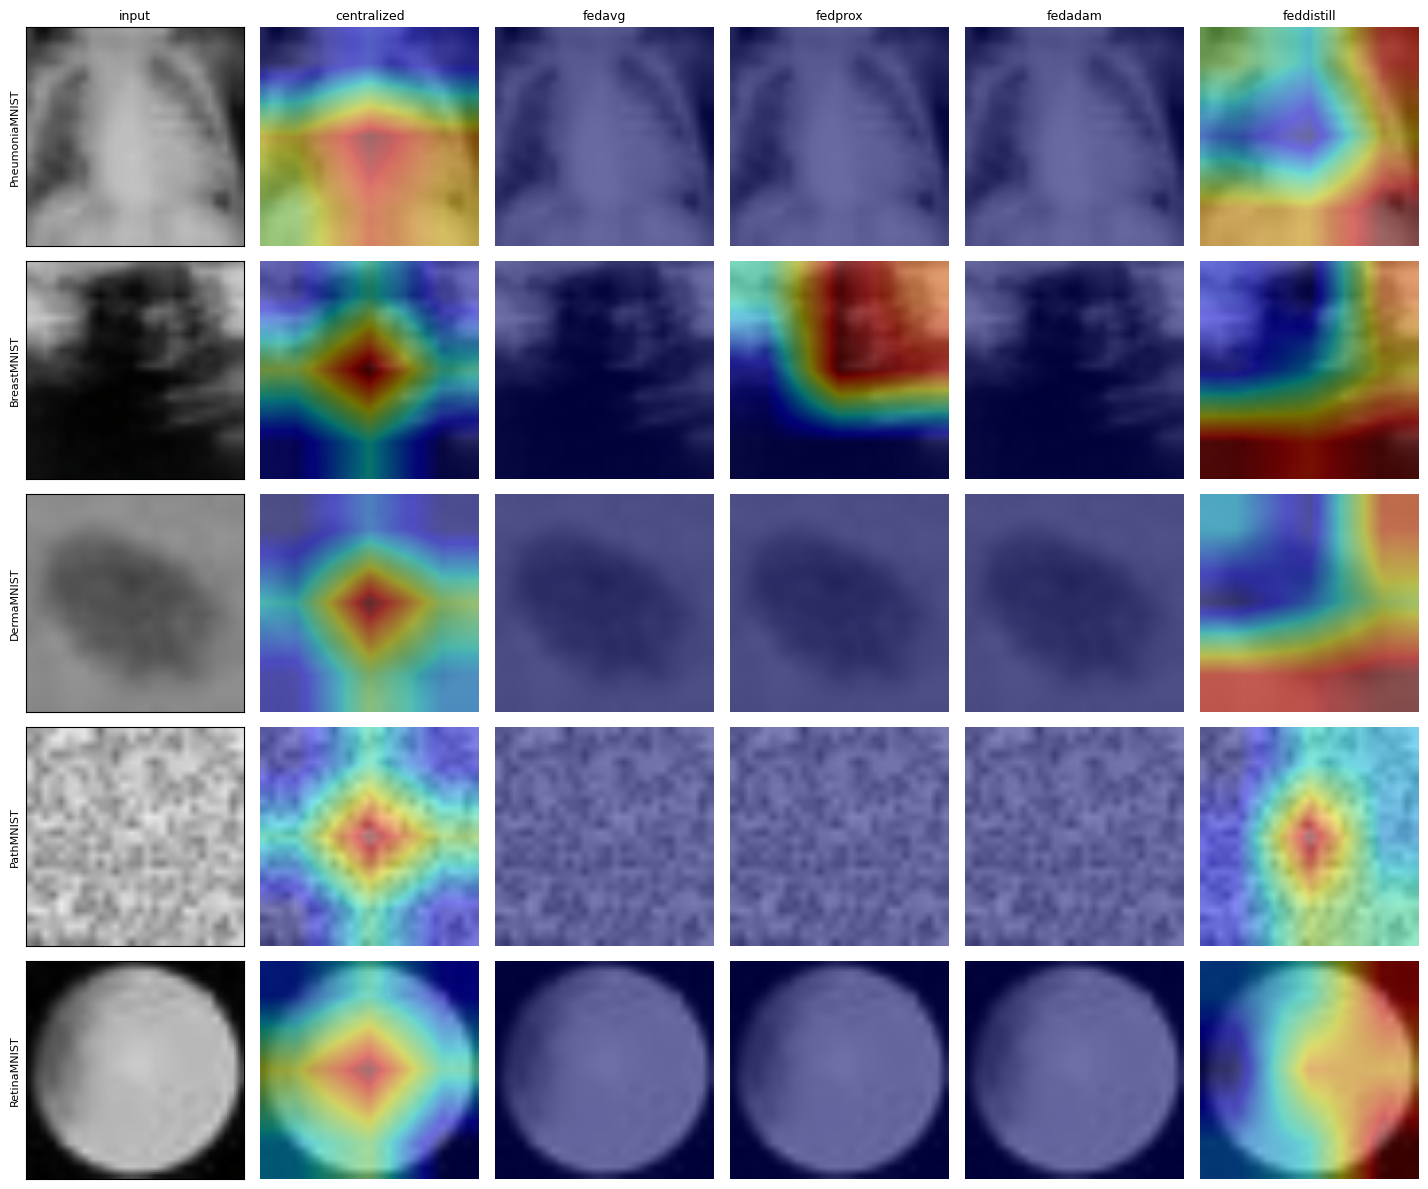


Grad-CAM top-20% region IoU between methods (mean over the 5 clients):
  centralized    vs fedavg         : 0.200
  centralized    vs fedprox        : 0.201
  centralized    vs fedadam        : 0.200
  centralized    vs feddistill     : 0.124
  fedavg         vs fedprox        : 0.840
  fedavg         vs fedadam        : 1.000
  fedavg         vs feddistill     : 0.201
  fedprox        vs fedadam        : 0.840
  fedprox        vs feddistill     : 0.160
  fedadam        vs feddistill     : 0.201


In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.activations = None
        self.gradients = None
        layer.register_forward_hook(self._forward)
        layer.register_full_backward_hook(self._backward)
    def _forward(self, module, inp, out):
        self.activations = out.detach()
    def _backward(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()
    def __call__(self, x, target=None):
        self.model.eval()
        self.model.zero_grad()
        out = self.model(x)
        if target is None:
            target = out.argmax(1)
        out.gather(1, target.view(-1, 1)).sum().backward()
        w = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.activations).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze(1)
        lo = cam.amin(dim=(1, 2), keepdim=True)
        hi = cam.amax(dim=(1, 2), keepdim=True)
        return ((cam - lo) / (hi - lo + 1e-8)).cpu().numpy(), target.cpu().numpy()

def unnormalize(img):
    x = img.permute(1, 2, 0).cpu().numpy() * np.array(imagenet_std) + np.array(imagenet_mean)
    return np.clip(x, 0, 1)

def cam_iou(a, b, q=0.8):
    ma = a >= np.quantile(a, q)
    mb = b >= np.quantile(b, q)
    return float((ma & mb).sum() / max((ma | mb).sum(), 1))

if RUN['explainability'] and MODELS:
    xai_methods = {}
    for key in [('centralized', CONFIG['seeds'][0]), ('fedavg', CONFIG['seeds'][0]),
                ('fedprox', CONFIG['seeds'][0]), ('fedadam', CONFIG['seeds'][0]),
                ('feddistill', CONFIG['seeds'][0])]:
        if key in MODELS:
            xai_methods[key[0]] = MODELS[key]

    samples = []
    for i, name in enumerate(CLIENTS['names']):
        img, lab = CLIENTS['test'][i][0]
        samples.append((name, img, lab))

    cams = {}
    for method, bundle in xai_methods.items():
        cams[method] = []
        explainers = {}
        for i, (name, img, lab) in enumerate(samples):
            model = bundle['model'] if method == 'centralized' else bundle['locals'][i]
            if id(model) not in explainers:
                explainers[id(model)] = GradCAM(model, model.backbone.layer4)
            cam, pred = explainers[id(model)](img.unsqueeze(0).to(DEVICE))
            cams[method].append(cam[0])

    fig, axes = plt.subplots(len(samples), len(cams) + 1, figsize=(2.4 * (len(cams) + 1), 2.4 * len(samples)))
    for r, (name, img, lab) in enumerate(samples):
        axes[r, 0].imshow(unnormalize(img))
        axes[r, 0].set_ylabel(name, fontsize=8)
        axes[r, 0].set_title('input' if r == 0 else '', fontsize=9)
        axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
        for c, method in enumerate(cams, start=1):
            axes[r, c].imshow(unnormalize(img))
            axes[r, c].imshow(cams[method][r], cmap='jet', alpha=0.45)
            axes[r, c].set_title(method if r == 0 else '', fontsize=9)
            axes[r, c].axis('off')
    plt.tight_layout()
    plt.savefig('gradcam_panel.png', dpi=140, bbox_inches='tight')
    plt.show()

    method_list = list(cams)
    print('\nGrad-CAM top-20% region IoU between methods (mean over the 5 clients):')
    for a, b in itertools.combinations(method_list, 2):
        ious = [cam_iou(cams[a][i], cams[b][i]) for i in range(len(samples))]
        record(RESULTS, experiment='explainability', method=f'{a} vs {b}', metric='cam_iou',
               value=float(np.mean(ious)), per_client=[round(v, 3) for v in ious])
        print(f'  {a:14s} vs {b:14s} : {np.mean(ious):.3f}')
else:
    print('explainability not run')

---
## 16. Shared representation across modalities

Three measurements, aimed at the question of whether federated training over five unrelated imaging
domains produces a representation that carries information across them, or whether each client ends
up with a private solution that happens to share a parameter vector.

1. **Linear CKA** between the penultimate features of the five client models on one common probe
   batch containing images from all modalities. High CKA means the clients encode the probe images
   similarly despite their local BatchNorm.
2. **t-SNE / PCA** of the federated features, coloured by client. If the embedding separates cleanly
   by modality, the representation is dominated by modality identity rather than by pathology.
3. **Linear probe transfer**: freeze the backbone, fit a logistic regression on each client's
   features, and compare the federated backbone against the plain ImageNet backbone. This is the
   quantitative version of "is the shared representation useful" — if the federated features give a
   better linear probe than ImageNet features on the same data, federated training added something.

"Common root cause" is interpreted here strictly as shared *representational* structure. Nothing in
this analysis can support a claim about a shared biological cause of these diseases, and none is made.

In [ ]:
def linear_cka(X, Y):
    X = X - X.mean(0, keepdims=True)
    Y = Y - Y.mean(0, keepdims=True)
    num = np.linalg.norm(Y.T @ X, 'fro') ** 2
    den = np.linalg.norm(X.T @ X, 'fro') * np.linalg.norm(Y.T @ Y, 'fro')
    return float(num / (den + 1e-12))

def features_of(model, X, batch=128):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(model.features(X[i:i + batch].to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

if RUN['representation'] and ('fedavg', CONFIG['seeds'][0]) in MODELS:
    probe_imgs, probe_client = [], []
    for i, name in enumerate(CLIENTS['names']):
        idx = np.random.RandomState(0).choice(len(CLIENTS['test'][i]), 60, replace=False)
        for j in idx:
            img, _ = CLIENTS['test'][i][int(j)]
            probe_imgs.append(img)
            probe_client.append(i)
    probe_X = torch.stack(probe_imgs)
    probe_client = np.array(probe_client)

    fed = MODELS[('fedavg', CONFIG['seeds'][0])]
    feats = [features_of(m, probe_X) for m in fed['locals']]

    cka = np.zeros((len(feats), len(feats)))
    for a in range(len(feats)):
        for b in range(len(feats)):
            cka[a, b] = linear_cka(feats[a], feats[b])
    off = cka[~np.eye(len(feats), dtype=bool)]
    record(RESULTS, experiment='representation', method='FedAvg', metric='mean_pairwise_cka',
           value=float(off.mean()), matrix=cka.round(3).tolist())
    print('Linear CKA between client backbones (FedAvg, shared probe batch):')
    print('        ' + ' '.join(f'{n[:6]:>7s}' for n in CLIENTS['names']))
    for i, n in enumerate(CLIENTS['names']):
        print(f'{n[:7]:8s}' + ' '.join(f'{v:7.3f}' for v in cka[i]))
    print(f'mean off-diagonal CKA: {off.mean():.3f}')

    emb = TSNE(n_components=2, init='pca', perplexity=25, random_state=0).fit_transform(
        PCA(n_components=50, random_state=0).fit_transform(features_of(fed['global'], probe_X)))
    plt.figure(figsize=(6, 5))
    for i, name in enumerate(CLIENTS['names']):
        sel = probe_client == i
        plt.scatter(emb[sel, 0], emb[sel, 1], s=12, label=name)
    plt.legend(fontsize=7)
    plt.title('t-SNE of federated backbone features, coloured by client')
    plt.tight_layout()
    plt.savefig('representation_tsne.png', dpi=140, bbox_inches='tight')
    plt.show()

    print('\nLinear probe on frozen features (train split, logistic regression):')
    imagenet_backbone = FederatedModel(2).to(DEVICE)
    for i, name in enumerate(CLIENTS['names']):
        idx = np.random.RandomState(0).choice(len(CLIENTS['train'][i]),
                                              min(600, len(CLIENTS['train'][i])), replace=False)
        Xi = torch.stack([CLIENTS['train'][i][int(j)][0] for j in idx])
        yi = np.array([CLIENTS['train'][i][int(j)][1] for j in idx])
        ti = np.random.RandomState(1).permutation(len(idx))
        tr, te = ti[:int(0.7 * len(ti))], ti[int(0.7 * len(ti)):]
        for tag, backbone in [('imagenet', imagenet_backbone), ('federated', fed['locals'][i])]:
            Z = features_of(backbone, Xi)
            clf = LogisticRegression(max_iter=2000).fit(Z[tr], yi[tr])
            acc = float(clf.score(Z[te], yi[te]))
            record(RESULTS, experiment='linear_probe', method=tag, client=name, accuracy=acc)
            print(f'  {name:16s} {tag:10s} probe acc {acc:.4f}')
else:
    print('representation analysis not run')

representation analysis not run


---
## 17. Tables and figures

Everything below is assembled from `RESULTS` and `HISTORY`. If an experiment was not run its table
prints "no records" instead of a number.

In [ ]:
def rows(**filters):
    out = []
    for r in RESULTS:
        if all(r.get(k) == v for k, v in filters.items()):
            out.append(r)
    return out

def agg(records, group_keys, value_keys):
    groups = {}
    for r in records:
        key = tuple(r.get(k) for k in group_keys)
        groups.setdefault(key, []).append(r)
    out = []
    for key, rs in groups.items():
        row = dict(zip(group_keys, key))
        for v in value_keys:
            vals = [r[v] for r in rs if r.get(v) is not None and not isinstance(r.get(v), (list, dict))]
            row[v] = (float(np.mean(vals)), float(np.std(vals)), len(vals)) if vals else None
        out.append(row)
    return out

def show(title, records, group_keys, value_keys, sort_by=None):
    print('\n' + title)
    if not records:
        print('  no records - experiment not run')
        return
    table = agg(records, group_keys, value_keys)
    if sort_by:
        table.sort(key=lambda r: (r[sort_by][0] if r.get(sort_by) else -1), reverse=True)
    width = {k: max(len(str(k)), max(len(str(r[k])) for r in table)) for k in group_keys}
    header = '  ' + ' | '.join(f'{k:{width[k]}s}' for k in group_keys) + ' | ' + \
             ' | '.join(f'{v:>16s}' for v in value_keys)
    print(header)
    print('  ' + '-' * (len(header) - 2))
    for r in table:
        cells = []
        for v in value_keys:
            if r[v] is None:
                cells.append(f'{"-":>16s}')
            elif r[v][2] > 1:
                cells.append(f'{r[v][0]:.4f}+-{r[v][1]:.3f}'.rjust(16))
            else:
                cells.append(f'{r[v][0]:.4f}'.rjust(16))
        print('  ' + ' | '.join(f'{str(r[k]):{width[k]}s}' for k in group_keys) + ' | ' + ' | '.join(cells))

print('TABLE 1 - dataset characteristics')
for r in TABLE1:
    print('  ', r)

main = [r for r in RESULTS if r['experiment'] in ('centralized', 'local_only', 'federated')
        and r.get('setting') == 'main']

show('TABLE 2/3 - centralized, local-only and federated, averaged over clients and seeds',
     main, ['method'], ['accuracy', 'f1', 'recall', 'auc', 'outside_rate'], sort_by='accuracy')

show('TABLE 3b - per client', main, ['method', 'client'], ['accuracy', 'f1', 'auc'])

show('TABLE 4 - communication and time',
     [r for r in main if r['experiment'] == 'federated'],
     ['method'], ['accuracy', 'f1', 'up_mb', 'down_mb', 'time_s'])

show('TABLE 5 - privacy mechanism (clipping + Gaussian noise on client updates; no formal epsilon)',
     rows(experiment='privacy'), ['dp_clip', 'dp_noise'], ['accuracy', 'f1', 'auc'])

show('TABLE 6 - new-disease transfer',
     rows(experiment='new_disease'), ['method', 'fraction'], ['accuracy', 'f1', 'auc'])

show('TABLE 7a - Grad-CAM agreement between methods',
     rows(experiment='explainability'), ['method'], ['value'])

show('TABLE 7b - linear probe on frozen features',
     rows(experiment='linear_probe'), ['method', 'client'], ['accuracy'])

show('TABLE 8 - label granularity sweep',
     [r for r in RESULTS if r.get('setting') in ('main', 'sweep')
      and r['experiment'] in ('centralized', 'federated') and r.get('classes')],
     ['method', 'classes'], ['accuracy', 'f1'])

show('TABLE 9 - Federated Distillation reference-set ablation (client models)',
     [r for r in RESULTS if r.get('algo') == 'feddistill'],
     ['n_public', 'sync_clients'], ['accuracy', 'f1', 'up_mb', 'down_mb'])

show('TABLE 9b - Federated Distillation server model',
     rows(experiment='distill_global'), ['n_public', 'sync_clients'], ['accuracy', 'f1'])

with open('results.json', 'w') as f:
    json.dump({'config': CONFIG, 'table1': TABLE1, 'results': RESULTS, 'history': HISTORY},
              f, indent=1, default=str)
print('\nsaved results.json')

TABLE 1 - dataset characteristics


NameError: name 'TABLE1' is not defined

In [ ]:
def history_curve(method, key='accuracy'):
    rs = [r for r in HISTORY if r['method'] == method]
    if not rs:
        return None, None
    rounds = sorted(set(r['round'] for r in rs))
    return rounds, [float(np.mean([r[key] for r in rs if r['round'] == x])) for x in rounds]

methods = sorted(set(r['method'] for r in HISTORY))
if methods:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for m in methods:
        x, y = history_curve(m, 'accuracy')
        axes[0].plot(x, y, '-o', ms=3, label=m)
        x, y = history_curve(m, 'f1')
        axes[1].plot(x, y, '-o', ms=3, label=m)
        rs = [r for r in HISTORY if r['method'] == m]
        rounds = sorted(set(r['round'] for r in rs))
        mb = [float(np.mean([r['cum_mb'] for r in rs if r['round'] == x])) for x in rounds]
        acc = [float(np.mean([r['accuracy'] for r in rs if r['round'] == x])) for x in rounds]
        axes[2].plot(mb, acc, '-o', ms=3, label=m)
    axes[0].set(xlabel='round', ylabel='mean accuracy', title='Accuracy vs rounds')
    axes[1].set(xlabel='round', ylabel='mean macro F1', title='F1 vs rounds')
    axes[2].set(xlabel='cumulative communication (MB)', ylabel='mean accuracy',
                title='Accuracy vs communication')
    axes[2].set_xscale('log')
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig('convergence_communication.png', dpi=140, bbox_inches='tight')
    plt.show()

nd = rows(experiment='new_disease')
priv = rows(experiment='privacy')
abl = [r for r in RESULTS if r.get('algo') == 'feddistill' and r.get('sync_clients') is True
       and r.get('setting') in ('main', 'ablation')]
panels = sum(x != [] for x in [nd, priv, abl])
if panels:
    fig, axes = plt.subplots(1, panels, figsize=(5.5 * panels, 4.2))
    axes = np.atleast_1d(axes)
    k = 0
    if nd:
        for init in sorted(set(r['method'] for r in nd)):
            fr = sorted(set(r['fraction'] for r in nd if r['method'] == init))
            acc = [float(np.mean([r['accuracy'] for r in nd if r['method'] == init and r['fraction'] == f]))
                   for f in fr]
            axes[k].plot(fr, acc, '-o', label=init)
        axes[k].set(xlabel='fraction of new-disease training data', ylabel='accuracy',
                    title=f'Bootstrapping {CONFIG["new_disease"]}')
        axes[k].legend(fontsize=8); axes[k].grid(alpha=0.3); k += 1
    if priv:
        lv = sorted(set(r['dp_noise'] for r in priv))
        acc = [float(np.mean([r['accuracy'] for r in priv if r['dp_noise'] == v])) for v in lv]
        f1 = [float(np.mean([r['f1'] for r in priv if r['dp_noise'] == v])) for v in lv]
        axes[k].plot(lv, acc, '-o', label='accuracy')
        axes[k].plot(lv, f1, '-s', label='macro F1')
        axes[k].set(xlabel='noise multiplier', ylabel='score', title='Noise vs utility')
        axes[k].legend(fontsize=8); axes[k].grid(alpha=0.3); k += 1
    if abl:
        sizes = sorted(set(r['n_public'] for r in abl))
        acc = [float(np.mean([r['accuracy'] for r in abl if r['n_public'] == s])) for s in sizes]
        up = [float(np.mean([r['up_mb'] for r in abl if r['n_public'] == s])) for s in sizes]
        axes[k].plot(sizes, acc, '-o', color='tab:blue')
        axes[k].set(xlabel='reference set size', ylabel='accuracy', title='FedDF reference-set ablation')
        ax2 = axes[k].twinx()
        ax2.plot(sizes, up, '--s', color='tab:red')
        ax2.set_ylabel('uplink MB', color='tab:red')
        axes[k].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('tradeoffs.png', dpi=140, bbox_inches='tight')
    plt.show()
else:
    print('no trade-off panels to plot')

---
## 18. Discussion, limitations and future work

*This section is written after the run. It contains no numbers until the tables above have actually
been produced — fill it in from `results.json` rather than from expectation.*

### Questions the experiments answer

- **Multiclass vs binary.** Compare Table 8 across `classes = 2, 3, 4, native`. The binary framing in
  the original notebook is a simplification, and the centralized/federated gap at native granularity
  is the honest measure of how hard the task really is.
- **Why federate.** Table 2/3 contains all three regimes. The interesting quantity is not
  federated-vs-centralized alone but where federated sits *between* local-only and centralized, per
  client. Small clients (BreastMNIST, RetinaMNIST) are where federation should pay off; large clients
  may lose relative to local-only, which is a real and reportable cost of federation.
- **General-purpose model.** In `union` mode, `outside_rate` says whether the 25-way head can be used
  without knowing the modality of the incoming image. A low within-client accuracy combined with a
  low outside_rate would mean the model has learned modality identity but not pathology.
- **Communication.** Table 4 gives measured MB. FedAvg, FedProx and FedAdam transmit the same volume;
  they differ only in what the server does with it. FedDF differs on the uplink only.
- **New disease.** Table 6 is only meaningful as the three-way comparison. If federated and ImageNet
  arms coincide, the honest conclusion is that federated training over these five domains added
  nothing transferable beyond ImageNet — that is a result, not a failure.

### Limitations to state explicitly

- Five clients, one client per dataset. This conflates "client heterogeneity" with "domain
  heterogeneity"; a realistic hospital federation would have many clients per modality. The
  experiment cannot separate the two effects.
- 28x28 MedMNIST images upsampled to 96x96. Conclusions may not transfer to full-resolution medical
  imaging.
- Training sets capped at `max_train_per_client`, which changes the natural size imbalance between
  clients and therefore the aggregation weights.
- The privacy experiment implements a mechanism, not a guarantee. No epsilon is reported.
- Grad-CAM is a diagnostic, not evidence. No clinical interpretation is offered.
- Runs use `CONFIG['seeds']`; with a single seed the differences between the weight-averaging methods
  are likely within run-to-run variance, and should be described that way rather than ranked.

### Future work

- DP-SGD with per-example gradient clipping and an RDP accountant (Opacus) to obtain a reportable
  (epsilon, delta), replacing the heuristic mechanism used here.
- Modality-specific input stems over a shared backbone, which is the natural architecture for genuinely
  multimodal federated learning. The current single-stem ResNet18 forces all five modalities through
  identical early filters, and the local-BatchNorm fix is a partial and cheap substitute for that.
- More clients per modality, to separate statistical heterogeneity from domain heterogeneity.
- Partial client participation and non-IID splits within a modality.

### Final research question

The version supported by this design:

> **In a federation of heterogeneous medical imaging domains, how much predictive performance does
> federated transfer learning give up relative to centralized training, how much does it gain over
> isolated local training, and what does it cost in communication and privacy — and does the
> resulting shared representation transfer to a disease no client contributed?**

Refine the wording once the tables are filled: if the new-disease arm shows no advantage over
ImageNet initialization, the transfer clause should be reported as a negative result rather than
dropped from the question.